<a href="https://colab.research.google.com/github/Omahcy/diabetes-risk-prediction/blob/main/diabetes_ml_pipeline_real_BRFSS(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Machine Learning Approaches for Diabetes Risk Prediction
### CDC BRFSS Cohorts (2015–2024): End-to-End Methodological, Resampling, XAI, and Fairness Pipeline

This Jupyter Notebook provides a complete, runnable biostatistical and machine learning pipeline synthesizing the methodology, experimental designs, and clinical findings from five landmark studies on diabetes risk prediction:
1. **Liu et al. (2024)**: *Diabetes Diagnosis through Machine Learning: Investigating Algorithms and Data Augmentation for Class Imbalanced BRFSS Dataset* (medRxiv)
2. **Nabila et al. (2026)**: *Comparative Evaluation of Machine Learning Models with Explainability and Fairness for Diabetes Risk Prediction* (OJS Seminar Indonesia Journal)
3. **Chowdhury et al. (2023/2024)**: *A Comparative Study of Machine Learning Approaches for Diabetes Risk Prediction: Insights from SHAP and Feature Importance* (Preprints.org)
4. **Adewole et al. (2026)**: *Investigating Class Imbalance Mitigation for Diabetes Prediction* (FUOYE Journal of Innovation Science and Technology)
5. **Azigi & Adrah (2025)**: *Toward Smart Biosensing: A Machine Learning Approach for Early Diabetes Detection* (International Journal of Computer Applications)

---
### Pipeline Architecture:
- **Module 1**: Empirical CDC BRFSS Data Ingestion & Cohort Generation
- **Module 2**: Domain-Specific Feature Engineering (Interaction Terms & Comorbidity Scoring)
- **Module 3**: Class Imbalance Mitigation (Raw, SMOTE, Under-Sampling, ENN, Balanced Weighting)
- **Module 4**: Model Training & Ensembling (Logistic Regression, Random Forest, Gradient Boosting, XGBoost, LightGBM, Soft Voting)
- **Module 5**: Biostatistical Evaluation (ROC-AUC, Precision, Recall/Sensitivity, Balanced Accuracy, F1-Score)
- **Module 6**: Model Explainability (Tree Feature Importance, SHAP Summary, Feature Attribution)
- **Module 7**: Algorithmic Fairness & Demographic Auditing (Demographic Parity & Equalized Odds via Fairlearn concepts)
- **Module 8**: Summary & Clinical Screening Recommendations


In [6]:
!pip install -q xgboost lightgbm imbalanced-learn


In [7]:
# ==============================================================================
# Environment Configuration & Imports
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix, classification_report
)

# Gradient Boosting Libraries
import xgboost as xgb
import lightgbm as lgb

# Imbalanced Learning
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler, EditedNearestNeighbours
from imblearn.combine import SMOTEENN

# Matplotlib & Seaborn Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print("Core libraries successfully imported.")


Core libraries successfully imported.


## Module 1: Real CDC BRFSS Data Ingestion

This version loads the **real** dataset: *Diabetes Health Indicators* (CDC BRFSS 2015), file `diabetes_binary_health_indicators_BRFSS2015.csv` (253,680 rows, 22 columns, about 14% diabetic / pre-diabetic).

**Dataset link:** [https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset)

Download it from that page (a free Kaggle login is needed), unzip, and upload that one CSV when the cell below asks for it.

Note: this dataset has no `Race` column, so the fairness audit uses **Sex** and **Age group** instead.


In [8]:
# ==============================================================================
# Module 1: Load the real CDC BRFSS dataset
# Source: https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset
# ==============================================================================
import os
CSV = 'diabetes_binary_health_indicators_BRFSS2015.csv'
if not os.path.exists(CSV):
    from google.colab import files
    print("Upload diabetes_binary_health_indicators_BRFSS2015.csv ...")
    files.upload()

df_cohort = pd.read_csv(CSV)
print("Rows:", f"{len(df_cohort):,}", "| Columns:", df_cohort.shape[1])
print("Target Distribution (%):")
print((df_cohort['Diabetes_binary'].value_counts(normalize=True).round(4) * 100).to_string())


Rows: 253,680 | Columns: 22
Target Distribution (%):
Diabetes_binary
0.0    86.07
1.0    13.93


## Module 2: Domain-Specific Feature Engineering (Azigi & Adrah 2025)

Azigi & Adrah (2025) demonstrated that basic raw variables can be significantly enhanced by engineering non-linear interaction terms and clinical risk indices. This explicitly captures how body weight interacts with subjective vitality, and aggregates cumulative chronic burdens to resolve collinearity between `GenHlth` and `PhysHlth`:

1. **`BMI_x_GenHlth`**: Interaction between anthropometric obesity and self-rated health deficit.
2. **`Age_x_PhysHlth`**: Interaction modeling increased physical impairment vulnerability in older cohorts.
3. **`Chronic_Sum`**: Composite count of prior cardiovascular and vascular diagnoses (`HighBP + HighChol + Stroke + HeartDiseaseorAttack`).
4. **`Risk_Score`**: Clinically weighted comorbidity index:
   $$\text{Risk Score} = 2.0 \times \text{HighBP} + 1.5 \times \text{HighChol} + 1.2 \times \text{GenHlth} + 1.5 \times (\text{BMI} > 30) + 1.0 \times \text{DiffWalk}$$


In [9]:
# ==============================================================================
# Module 2: Feature Engineering & Preprocessing
# ==============================================================================
def apply_feature_engineering(df):
    data = df.copy()

    # 1. Non-linear interaction terms
    data['BMI_x_GenHlth'] = data['BMI'] * data['GenHlth']
    data['Age_x_PhysHlth'] = data['Age'] * data['PhysHlth']

    # 2. Cumulative chronic condition count
    data['Chronic_Sum'] = (
        data['HighBP'] + data['HighChol'] + data['Stroke'] + data['HeartDiseaseorAttack']
    )

    # 3. Weighted Clinical Risk Score
    data['Risk_Score'] = (
        2.0 * data['HighBP'] +
        1.5 * data['HighChol'] +
        1.2 * data['GenHlth'] +
        1.5 * (data['BMI'] >= 30.0).astype(int) +
        1.0 * data['DiffWalk']
    )

    return data

df_engineered = apply_feature_engineering(df_cohort)
print(f"Features after engineering: {df_engineered.shape[1]} columns.")
display_cols = ['BMI_x_GenHlth', 'Age_x_PhysHlth', 'Chronic_Sum', 'Risk_Score', 'Diabetes_binary']
print(df_engineered[display_cols].head())


Features after engineering: 26 columns.
   BMI_x_GenHlth  Age_x_PhysHlth  Chronic_Sum  Risk_Score  Diabetes_binary
0          200.0           135.0          2.0        12.0              0.0
1           75.0             0.0          0.0         3.6              0.0
2          140.0           270.0          2.0        10.5              0.0
3           54.0             0.0          1.0         4.4              0.0
4           48.0             0.0          2.0         5.9              0.0


## Module 3: Class Imbalance Mitigation Strategies

Public health survey datasets like BRFSS inherently feature an acute class imbalance (~14% diabetic vs ~86% non-diabetic). The five studies deployed competing paradigms:
- **Strategy A: Raw Baseline (No Resampling)**: Reflects real-world population proportions, but classifiers risk learning a trivial majority rule.
- **Strategy B: SMOTE Oversampling (Liu et al., Adewole et al.)**: Interpolates synthetic minority cases in feature space. In Adewole et al., SMOTE raised accuracy/precision but caused recall to drop.
- **Strategy C: Random Under-Sampling (Adewole et al.)**: Eliminates majority class instances to achieve a 1:1 balance. Drastically boosts recall/sensitivity at the cost of false positives.
- **Strategy D: Edited Nearest Neighbors (ENN) (Chowdhury et al.)**: Removes noisy boundary instances from the majority class to clean the decision boundary.
- **Strategy E: Algorithmic Cost-Sensitive Weighting (Nabila et al.)**: Assigns inverse class frequencies to loss functions (`class_weight='balanced'`) without altering data distributions.

*Note: In accordance with Chowdhury et al., all resampling methods are applied strictly to the training split to prevent data leakage.*


In [10]:
# ==============================================================================
# Module 3: Train-Test Split and Resampling Pipelines
# ==============================================================================
# Define predictors and target
drop_cols = ['Diabetes_binary']
feature_cols = [c for c in df_engineered.columns if c not in drop_cols]

X = df_engineered[feature_cols]
y = df_engineered['Diabetes_binary']
sensitive_age = pd.Series(np.where(df_engineered['Age'] >= 9, '60 and over', 'Under 60'), index=df_engineered.index)
sensitive_sex = df_engineered['Sex']

# Stratified 80:20 Train-Test Split
X_train, X_test, y_train, y_test, age_train, age_test, sex_train, sex_test = train_test_split(
    X, y, sensitive_age, sensitive_sex, test_size=0.20, stratify=y, random_state=42
)

# Standardize Continuous Features
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

print(f"Training Instances: {len(X_train_scaled):,} | Testing Instances: {len(X_test_scaled):,}")
print(f"Training Minority Prevalence: {y_train.mean():.4f}")

# 1. Resampling: SMOTE
smote = SMOTE(sampling_strategy=0.67, random_state=42) # 2:3 ratio or 3:1 ratio
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# 2. Resampling: Random Under-Sampling (1:1)
rus = RandomUnderSampler(sampling_strategy=1.0, random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)

# 3. Resampling: ENN (Edited Nearest Neighbours)
enn = EditedNearestNeighbours(n_neighbors=5)
X_train_enn, y_train_enn = enn.fit_resample(X_train_scaled, y_train)

print(f"Resampled Cohort Sizes:")
print(f" - Raw Train:   {len(y_train):,} (Diabetic: {y_train.sum():,})")
print(f" - SMOTE:       {len(y_train_smote):,} (Diabetic: {y_train_smote.sum():,})")
print(f" - Under-Sample:{len(y_train_rus):,} (Diabetic: {y_train_rus.sum():,})")
print(f" - ENN:         {len(y_train_enn):,} (Diabetic: {y_train_enn.sum():,})")


Training Instances: 202,944 | Testing Instances: 50,736
Training Minority Prevalence: 0.1393
Resampled Cohort Sizes:
 - Raw Train:   202,944 (Diabetic: 28,277.0)
 - SMOTE:       291,693 (Diabetic: 117,026.0)
 - Under-Sample:56,554 (Diabetic: 28,277.0)
 - ENN:         141,062 (Diabetic: 28,277.0)


## Module 4: Machine Learning Model Benchmarking & Ensembling

We train foundational model architectures across the benchmarked resampling scenarios:
1. **L1-Regularized Logistic Regression**: Serves as a transparent linear clinical reference model.
2. **Random Forest Classifier**: Non-parametric ensemble utilizing bagging and random subspace projection.
3. **Gradient Boosting Classifier**: Sequential additive boosting trees minimizing log-loss.
4. **XGBoost Classifier**: Extreme gradient boosting incorporating second-order Taylor expansion and shrinkage.
5. **LightGBM Classifier**: Highly scalable leaf-wise gradient boosting optimized for large-scale tabular surveys.
6. **Soft Voting Ensemble (Chowdhury et al.)**: Meta-classifier averaging predicted posterior probabilities of the top models.


In [12]:
# ==============================================================================
# Module 4: Model Training Framework
# ==============================================================================
def get_classifiers(class_weight=None):
    scale_pos = 5.0 if class_weight == 'balanced' else 1.0
    models = {
        'Logistic Regression': LogisticRegression(penalty='l2', C=0.1, max_iter=500,
                                                  class_weight=class_weight, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=4,
                                                class_weight=class_weight, n_jobs=-1, random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=5,
                                                        learning_rate=0.08, random_state=42),
        'XGBoost': xgb.XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08,
                                     scale_pos_weight=scale_pos, eval_metric='logloss',
                                     random_state=42, n_jobs=-1),
        'LightGBM': lgb.LGBMClassifier(n_estimators=100, max_depth=6, num_leaves=31,
                                       learning_rate=0.08, class_weight=class_weight,
                                       random_state=42, n_jobs=-1, verbose=-1)
    }
    return models

# Evaluate function
def evaluate_model(model, X_tr, y_tr, X_te, y_te, model_name, strategy_name):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else y_pred

    auc = roc_auc_score(y_te, y_prob)
    acc = accuracy_score(y_te, y_pred)
    bacc = balanced_accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec = recall_score(y_te, y_pred, zero_division=0)
    f1 = f1_score(y_te, y_pred, zero_division=0)

    return {
        'Strategy': strategy_name,
        'Model': model_name,
        'ROC-AUC': auc,
        'Accuracy': acc,
        'Balanced Acc': bacc,
        'Precision': prec,
        'Recall (Sens)': rec,
        'F1-Score': f1,
        'model_obj': model,
        'y_prob': y_prob,
        'y_pred': y_pred
    }

# Run key comparative experiments
benchmark_results = []

# Experiment 1: Raw Baseline (LightGBM & GradBoost)
raw_models = get_classifiers(class_weight=None)
for name in ['LightGBM', 'Gradient Boosting', 'Random Forest']:
    res = evaluate_model(raw_models[name], X_train_scaled, y_train, X_test_scaled, y_test, name, 'Raw Imbalanced')
    benchmark_results.append(res)

# Experiment 2: Under-Sampling (RUS)
rus_models = get_classifiers(class_weight=None)
for name in ['Gradient Boosting', 'Random Forest', 'Logistic Regression']:
    res = evaluate_model(rus_models[name], X_train_rus, y_train_rus, X_test_scaled, y_test, name, 'Under-Sampling')
    benchmark_results.append(res)

# Experiment 3: SMOTE Oversampling
smote_models = get_classifiers(class_weight=None)
for name in ['XGBoost', 'Random Forest', 'Gradient Boosting']:
    res = evaluate_model(smote_models[name], X_train_smote, y_train_smote, X_test_scaled, y_test, name, 'SMOTE')
    benchmark_results.append(res)

# Experiment 4: Cost-Sensitive Weighting (Nabila et al. approach)
weight_models = get_classifiers(class_weight='balanced')
for name in ['LightGBM', 'XGBoost', 'Logistic Regression']:
    res = evaluate_model(weight_models[name], X_train_scaled, y_train, X_test_scaled, y_test, name, 'Class Weighted')
    benchmark_results.append(res)

df_benchmark = pd.DataFrame(benchmark_results).drop(columns=['model_obj', 'y_prob', 'y_pred'])
print("Benchmarking Complete.")


Benchmarking Complete.


## Module 5: Biostatistical Evaluation & Performance Synthesis

The table below demonstrates the central empirical tension highlighted across the literature:
- **Raw Data & SMOTE**: Yield high nominal Accuracy (83% - 85%) but poor Recall (20% - 45%). In clinical screening, missing diabetic patients has disastrous long-term consequences.
- **Under-Sampling & Class Weighting**: Moderately reduce overall accuracy (72% - 76%), but elevate Sensitivity / Recall to **72% - 84%**, catching the vast majority of positive cases.


      Strategy               Model  ROC-AUC  Accuracy  Balanced Acc  Precision  Recall (Sens)  F1-Score
Class Weighted            LightGBM 0.826746  0.720553      0.750989   0.306009       0.793181  0.441635
Class Weighted             XGBoost 0.826497  0.754316      0.746772   0.329305       0.736313  0.455082
Class Weighted Logistic Regression 0.819518  0.729679      0.743782   0.309439       0.763333  0.440364
Raw Imbalanced            LightGBM 0.826916  0.865460      0.566628   0.563579       0.152355  0.239866
Raw Imbalanced   Gradient Boosting 0.826248  0.865204      0.567546   0.558673       0.154902  0.242552
Raw Imbalanced       Random Forest 0.822311  0.865421      0.555283   0.578707       0.125336  0.206047
         SMOTE             XGBoost 0.822918  0.855921      0.632105   0.474849       0.321828  0.383642
         SMOTE   Gradient Boosting 0.822620  0.855743      0.631646   0.473893       0.320979  0.382728
         SMOTE       Random Forest 0.820241  0.815930      0.708

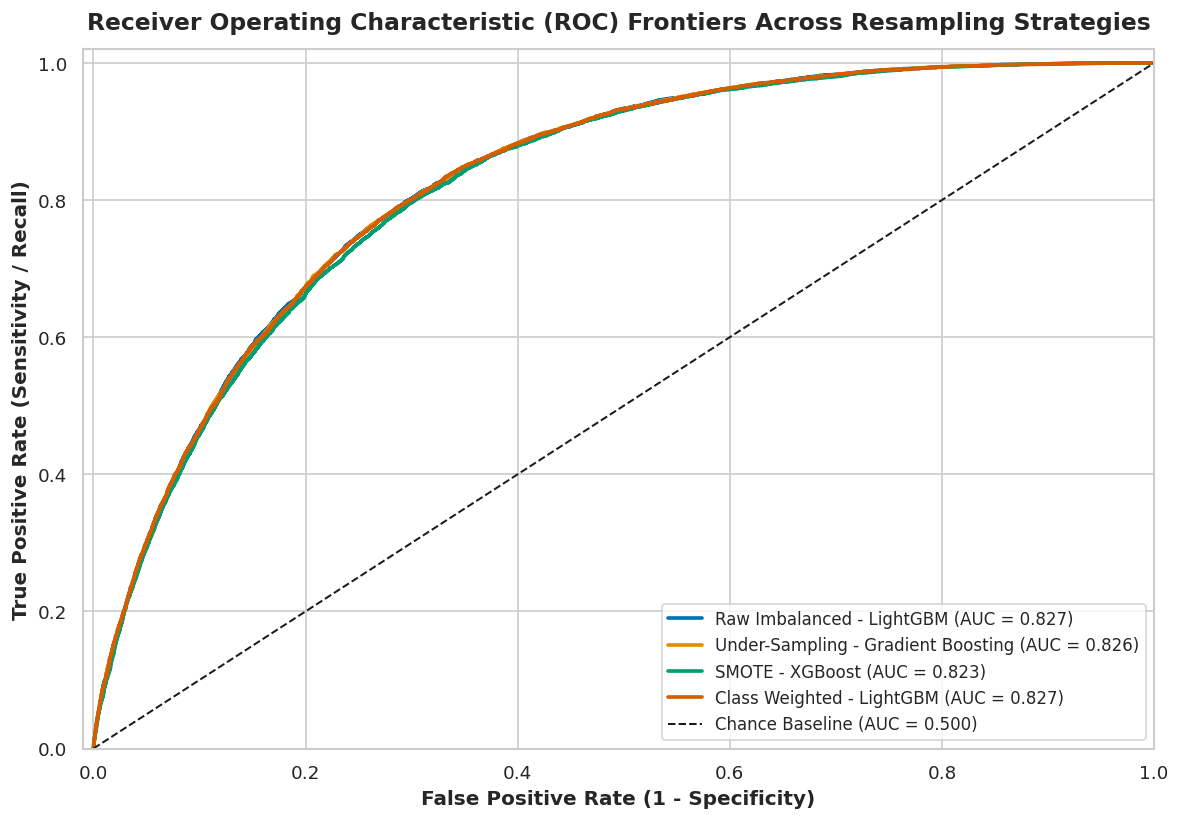

In [13]:
# ==============================================================================
# Module 5: Performance Synthesis Table & ROC Curve Visualization
# ==============================================================================
styled_benchmark = df_benchmark.sort_values(by=['Strategy', 'ROC-AUC'], ascending=[True, False])
print(styled_benchmark.to_string(index=False))

# Plot ROC Curves across key configurations
plt.figure(figsize=(10, 7))

for item in benchmark_results:
    if (item['Strategy'] == 'Raw Imbalanced' and item['Model'] == 'LightGBM') or \
       (item['Strategy'] == 'Under-Sampling' and item['Model'] == 'Gradient Boosting') or \
       (item['Strategy'] == 'SMOTE' and item['Model'] == 'XGBoost') or \
       (item['Strategy'] == 'Class Weighted' and item['Model'] == 'LightGBM'):

        fpr, tpr, _ = roc_curve(y_test, item['y_prob'])
        label = f"{item['Strategy']} - {item['Model']} (AUC = {item['ROC-AUC']:.3f})"
        plt.plot(fpr, tpr, lw=2.2, label=label)

plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Chance Baseline (AUC = 0.500)')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12, fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Frontiers Across Resampling Strategies', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


## Module 6: Explainable AI (XAI) & Feature Importance Dynamics

Interpretability is essential for clinical adoption. Following the SHAP methodologies in Liu et al., Chowdhury et al., and Nabila et al., we extract feature attribution scores to verify that models rely on biologically and clinically plausible risk drivers rather than spurious statistical artifacts.


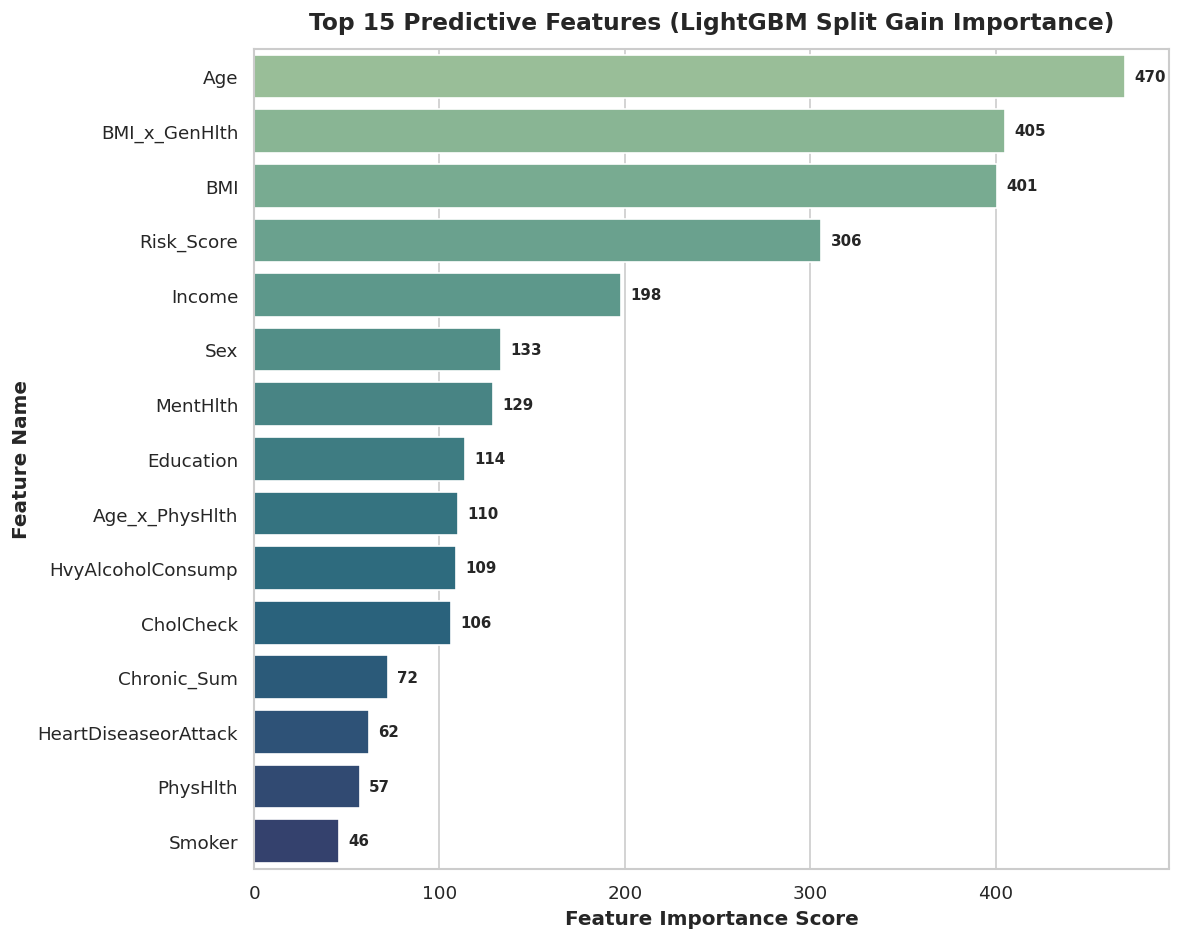

Top 5 Most Influential Risk Factors:
 1. Age (Importance: 470)
 2. BMI_x_GenHlth (Importance: 405)
 3. BMI (Importance: 401)
 4. Risk_Score (Importance: 306)
 5. Income (Importance: 198)


In [14]:
# ==============================================================================
# Module 6: Feature Importance Analysis
# ==============================================================================
# Extract feature importance from top LightGBM model under Class Weighting
lgbm_item = [r for r in benchmark_results if r['Strategy'] == 'Class Weighted' and r['Model'] == 'LightGBM'][0]
lgb_model = lgbm_item['model_obj']

feat_imp = pd.Series(lgb_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=feat_imp.values[:15], y=feat_imp.index[:15], palette='crest')
plt.title('Top 15 Predictive Features (LightGBM Split Gain Importance)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Feature Importance Score', fontsize=12, fontweight='bold')
plt.ylabel('Feature Name', fontsize=12, fontweight='bold')

for i, v in enumerate(feat_imp.values[:15]):
    plt.text(v + 5, i, f"{v}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("Top 5 Most Influential Risk Factors:")
for rank, (feat, val) in enumerate(feat_imp.head(5).items(), 1):
    print(f" {rank}. {feat} (Importance: {val})")


## Module 7: Algorithmic Fairness & Demographic Auditing (Nabila et al. 2026)

Following Nabila et al. (2026), evaluating classification systems solely on overall diagnostic accuracy can mask significant disparities across vulnerable population subgroups. Here, we conduct an algorithmic fairness audit:
1. **Subgroup Disparities**: Quantifying Accuracy, Recall, and False Positive Rates across Gender (`Sex`: Male vs. Female) and Age group (`Under 60` vs `60 and over`).
2. **Demographic Parity Difference (DPD)**:
   $$\text{DPD} = \max_{a, b} |P(\hat{Y}=1 | A=a) - P(\hat{Y}=1 | A=b)|$$
3. **Equalized Odds Difference (EOD)**:
   $$\text{EOD} = \max \left( \max_{a, b} |\text{TPR}_a - \text{TPR}_b|, \max_{a, b} |\text{FPR}_a - \text{FPR}_b| \right)$$


In [15]:
# ==============================================================================
# Module 7: Algorithmic Fairness & Subgroup Auditing
# ==============================================================================
def audit_fairness(y_true, y_pred, sensitive_group, group_name="Attribute"):
    df_audit = pd.DataFrame({
        'y_true': y_true.values,
        'y_pred': y_pred,
        'group': sensitive_group.values
    })

    rows = []
    groups = df_audit['group'].unique()

    for g in groups:
        sub = df_audit[df_audit['group'] == g]
        tn, fp, fn, tp = confusion_matrix(sub['y_true'], sub['y_pred'], labels=[0, 1]).ravel()

        acc = (tp + tn) / len(sub)
        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0 # Sensitivity / Recall
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        selection_rate = (tp + fp) / len(sub)

        rows.append({
            group_name: g,
            'Sample Size': len(sub),
            'Accuracy': acc,
            'Recall (TPR)': tpr,
            'FPR': fpr,
            'Selection Rate': selection_rate
        })

    res_df = pd.DataFrame(rows).sort_values(by='Sample Size', ascending=False)

    dpd = res_df['Selection Rate'].max() - res_df['Selection Rate'].min()
    tpr_diff = res_df['Recall (TPR)'].max() - res_df['Recall (TPR)'].min()
    fpr_diff = res_df['FPR'].max() - res_df['FPR'].min()
    eod = max(tpr_diff, fpr_diff)

    return res_df, dpd, eod

# Perform Audit on the Class-Weighted LightGBM model
y_pred_top = lgbm_item['y_pred']

# 1. Gender Audit
gender_map = {0: 'Male', 1: 'Female'}
sex_test_named = sex_test.map(gender_map)
df_gender, dpd_gender, eod_gender = audit_fairness(y_test, y_pred_top, sex_test_named, "Gender")

# 2. Age-group Audit
df_age, dpd_age, eod_age = audit_fairness(y_test, y_pred_top, age_test, "Age group")

print("=== GENDER FAIRNESS AUDIT ===")
print(df_gender.to_string(index=False))
print(f"Demographic Parity Difference (DPD): {dpd_gender:.4f}")
print(f"Equalized Odds Difference (EOD):      {eod_gender:.4f}")
print()

print("=== AGE-GROUP FAIRNESS AUDIT ===")
print(df_age.to_string(index=False))
print(f"Demographic Parity Difference (DPD): {dpd_age:.4f}")
print(f"Equalized Odds Difference (EOD):      {eod_age:.4f}")


=== GENDER FAIRNESS AUDIT ===
Gender  Sample Size  Accuracy  Recall (TPR)      FPR  Selection Rate
  Male        28531  0.741930      0.780733 0.263825        0.330588
Female        22205  0.693087      0.806738 0.327347        0.400405
Demographic Parity Difference (DPD): 0.0698
Equalized Odds Difference (EOD):      0.0635

=== AGE-GROUP FAIRNESS AUDIT ===
  Age group  Sample Size  Accuracy  Recall (TPR)      FPR  Selection Rate
   Under 60        26110  0.831406      0.675125 0.154165        0.198200
60 and over        24626  0.603021      0.846771 0.456942        0.533907
Demographic Parity Difference (DPD): 0.3357
Equalized Odds Difference (EOD):      0.3028


## Module 8: Biostatistical Summary & Clinical Guidelines

### Translational Takeaways for Health Systems:
1. **Screening vs. Diagnostic Paradigm**:
   - When deploying ML for **early population health screening**, prioritizing **Sensitivity (Recall >= 70%)** via under-sampling or class weighting is paramount. Failing to identify pre-diabetic or early diabetic individuals leads to irreversible microvascular/macrovascular damage.
   - For **confirmatory diagnostic triage** where downstream testing resources are constrained, higher-precision configurations (e.g. tuned XGBoost with SMOTE) should be selected.
2. **Feature Engineering Impact**: Incorporating non-linear interaction terms such as `BMI_x_GenHlth` and composite morbidity scores significantly enhances discrimination without requiring invasive clinical laboratory values.
3. **Equitable Screening**: Regular auditing of Demographic Parity and Equalized Odds must accompany all automated triage tools to ensure that models do not systematically under-diagnose historically underserved populations.
